<a href="https://colab.research.google.com/github/danielzhang122/radioisotope-workshop/blob/main/Radioisotope_Production_Fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction and Welcome

Welcome to NAYGN McMaster's Radioisotope Production Fundamentals Workshop!

This notebook is an interactive tool used to participate in the live workshop. Students can follow along with the slides for information on workshop topics before putting their skills to use in this workshop.

To edit this workshop, create a copy of the notebook and save to your personal drive (this copy is locked for editing). To save a copy, navigate to File --> Save a Copy in Drive.

For any questions, please feel free to ask one of the presenters at the workshop. For any asynchronous work, please contact powerm12@mcmaster.ca or contact NAYGN through one of the affiliated social media accounts.

# Programming in Google Colab Basics

Google Colab is a free collaborative Jupyter Notebook system available to anyone with a Google account.

The program uses cells of text and code, where code cells can be run to generate outputs. The outputs of any code cells will be shown beneath the cell. Each code cell has a set of parentheses, [ ], on the left hand side.

To run a cell, hit "CTRL + Enter". Try it on the code cell below. A cell that has been successfully run will have a check mark!



In [1]:
print("Welcome to NAYGN McMaster's 4th Technical Workshop of the 2026/27 Academic Year!")

Welcome to NAYGN McMaster's 4th Technical Workshop of the 2026/27 Academic Year!


Workshop participants will only be required to outline a few variables and function inputs. The rest of the code has been premade so students can focus on the physics behind the activities.

If you have any questions, please let the presenter or one of the other NAYGN team members know!

A solutions manual for each activity is also available at the end of the PowerPoint slides.

# Activity 1 (Recap) - Modelling a Parent-Daughter Decay Chain

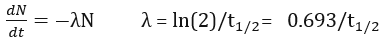

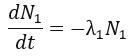 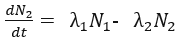

Using the equations above and slides 10,11 of the PowerPoint slides, solve for the decay constant of both isotopes in the first "TO-DO" section.

With the decay constants solved, solve the second "TO_DO" section by using the dN/dt equations for N1, N2.

Participants are recommended to copy & paste variable names like "N_Br80" or "half_life_Kr80" where possible to avoid syntax errors!

With the "TO_DO" sections solved, run the code cell and view the figure below. Does the output match your expectations?

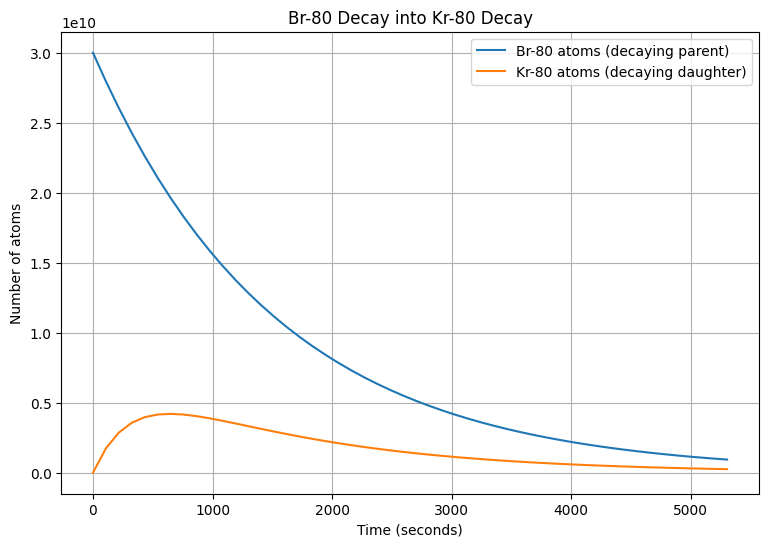

In [4]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

# Initial Conditions and Nuclear Info

N_Br80 = 3e10   #initial quantity of Br-80 (parent)
N_Kr80 = 0  #initial quantity of Kr-80 (daughter)

half_life_Br80 = 1060.8       # Br-80 half-life in seconds
half_life_Kr80 = 226      # Kr-80 half-life in seconds

# ----------------------------------------------------
# TO-DO: Convert provided half-lives into lambda values
# ----------------------------------------------------

lambda_Br80 = 0.693/half_life_Br80   #solve for Br-80 Decay Constant

lambda_Kr80 = 0.693/half_life_Kr80  #solve for Kr-80 Decay Constant

# ----------------------------------------------------
# TO-DO: Solve using the Bateman equations from the PPT
# ----------------------------------------------------

def dNdt(N, t):
    N_Br80, N_Kr80 = N

    dN_Br80 = -lambda_Br80 * N_Br80    #parent

    dN_Kr80 = -dN_Br80 - lambda_Kr80 * N_Kr80 #daughter

    return [dN_Br80, dN_Kr80]

# Time grid (5 * parent half life)

t_seconds = np.linspace(0, 5 * half_life_Br80)

# Solve ODE system
initial_conditions = [N_Br80, N_Kr80]
solution = odeint(dNdt, initial_conditions, t_seconds)

N_Br80_solution = solution[:, 0]
N_Kr80_solution = solution[:, 1]

# Plot results

plt.figure(figsize=(9, 6))
plt.plot(t_seconds, N_Br80_solution, label="Br-80 atoms (decaying parent)")
plt.plot(t_seconds, N_Kr80_solution, label="Kr-80 atoms (decaying daughter)")
plt.xlabel("Time (seconds)")
plt.ylabel("Number of atoms")
plt.title("Br-80 Decay into Kr-80 Decay")
plt.grid(True)
plt.legend()
plt.show()

# Activity 2 - Modelling Cobalt-60 Production in a Nuclear Reactor

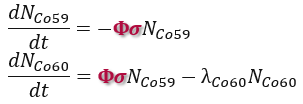

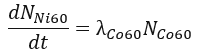

Using the equations above and slides 19, 20 of the PowerPoint slides, solve for the decay constants of the new isotopes in the first "TO_DO" section before using the new variables provided to model the production inside the reactor!

Note that phi and sigma are provided in the code. Also, make sure to solve for each of the three dN/dt equations!

Once you've entered each equation, run the code cell and compare the output to Activity 1.

In [ ]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

# Initial Conditions and Nuclear Info

seconds_per_year = 365 * 24 * 3600

N_Co59 = 1e15   #initial quantity of stable Cobalt-59
N_Co60 = 0      #initial quantity of unstable Cobalt-60
N_Ni60 = 0      #initial quantity of stable Nickel-60

half_life_Co60 = 5.27      # Cobalt-60 half-life in years
phi = 1e14                 # example neutron flux in the reactor (n/cm^2/s)
sigma = 37.5e-24           # activation cross section of Co-59 (cm^2)

# ----------------------------------------------------
# TO-DO: Solve for Cobalt-60 Decay Constant
# HINT: Make sure to convert the half life to seconds!
# HINT: You are given a seconds to year conversion variable! Scroll up!
# ----------------------------------------------------

lambda_Co60 =  NONE

# ----------------------------------------------------
# TO-DO: Solve using the production equations from the PPT
# ----------------------------------------------------

def dNdt(N, t):
    N_Co59, N_Co60, N_Ni60 = N

    dN_Co59 = NONE    # Co59 is lost to make Co60

    dN_Co60 = NONE

    dN_Ni60 = NONE         # Co60's loss is Ni60's gain

    return [dN_Co59, dN_Co60, dN_Ni60]


# Time grid (5 * Cobalt-60 half-life)

t_years = np.linspace(0, 5 * half_life_Co60)
t_seconds = t_years * seconds_per_year

# Solve ODE system

initial_conditions = [N_Co59, N_Co60, N_Ni60]
solution = odeint(dNdt, initial_conditions, t_seconds)

Co59_solution = solution[:, 0]
Co60_solution = solution[:, 1]
Ni60_solution = solution[:, 2]

# Plot results

plt.figure(figsize=(9, 6))
plt.plot(t_years, Co59_solution, label="Co-59 atoms (depleting)")
plt.plot(t_years, Co60_solution, label="Co-60 atoms (producing - decay)")
plt.plot(t_years, Ni60_solution, label="Ni-60 atoms (gaining from Co60 decay)")
plt.xlabel("Time (years)")
plt.ylabel("Number of atoms")
plt.title("Cobalt-60 Production from Cobalt-59")
plt.grid(True)
plt.legend()
plt.show()

# Activity 3 - Simulating Decay Chain Branching

To simulate decay branches on the same decay chain, use branching ratios (denoted below as br1 and br2) to multiply the dN/dt equations for each of the daughter isotopes (Zn64 and Ni64).

With the branching ratios added, compare the output quantity of each daughter isotope to the total output.

Note: The daughter isotopes (Zn64 and Ni64) are stable and do not decay further, so each dN/dt equation should only have a single term!

In [ ]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

# Initial Conditions and Nuclear Info
# NOTE: We are now using hours, not years from the prev. example

seconds_per_hour = 3600

N_Cu64 = 1e15   #initial quantity of unstable Copper-64
N_Zn64 = 0      #initial quantity of stable Zinc-64
N_Ni64 = 0      #initial quantity of stable Nickel-64

half_life_Cu64 = 12.7      # Copper-64 half-life in hours

#branching ratios

br1 = 0.385        #ratio of decay to Zinc-64
br2 = 1.0 - br1    #ratio of decay to Nickel-64

# ----------------------------------------------------
# TO-DO: Solve for Copper-64 Decay Constant
# HINT: Make sure to convert the half life to seconds!
# ----------------------------------------------------

lambda_Cu64 =  NONE

# ----------------------------------------------------
# TO-DO: Solve using the branching ratios above
# ----------------------------------------------------

def dNdt(N, t):
    N_Cu64, N_Zn64, N_Ni64 = N

    dN_Cu64 = NONE

    dN_Zn64 = NONE

    dN_Ni64 = NONE

    return [dN_Cu64, dN_Zn64, dN_Ni64]

# ----------------------------------------------------
# Time grid (8 * Copper-64 half-life)
# ----------------------------------------------------

t_hours = np.linspace(0, 8 * half_life_Cu64)
t_seconds = t_hours * seconds_per_hour

# ----------------------------------------------------
# Solve ODE system
# ----------------------------------------------------

initial_conditions = [N_Cu64, N_Zn64, N_Ni64]
solution = odeint(dNdt, initial_conditions, t_seconds)

Cu64_solution = solution[:, 0]
Zn64_solution = solution[:, 1]
Ni64_solution = solution[:, 2]

# ----------------------------------------------------
# Plot results
# ----------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(t_hours, Cu64_solution, label="Cu-64 atoms (depleting)")
plt.plot(t_hours, Zn64_solution, label="Zn-64 atoms (producing)")
plt.plot(t_hours, Ni64_solution, label="Ni-64 atoms (producing)")

plt.xlabel("Time (years)")
plt.ylabel("Number of atoms")
plt.title("Copper-64 Decay Branches")
plt.grid(True)
plt.legend()

plt.show()

# Activity 4 - Custom Radioisotope Production Model

In this activity, students will combine techniques from previous learning and take the role of an engineer/scientist overseeing the production of a sample radioisotope.

Participants will build and optimize a model demonstrating the production of Actinium-225 (Ac-225), a rare and sought after synthetic isotope used for cancer treatment.

Participants will begin by building the necessary steps from the decay chain (Rc-225 to Ac-225) to observe the base system. Once built, participants have free reign to change parameters to optimize the solution or change the problem as they see fit!

Ensure the TO-DO sections are filled out and the cell output runs before beginning optimization. Good luck!

In [ ]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

# ----------------------------------------------------
# USER MODIFIED PARAMETERS
# ----------------------------------------------------

elution_interval_days = 20   # Time between each harvest (days)
total_time_days = 60.0       # Total duration production (days)
N_Ra225_initial = 1.0e23     # Initial quantity of parent

# Nuclear Info & Time Constants

seconds_per_day = 86400

half_life_Ra225 = 15.0    #half life of parent
half_life_Ac225 = 10.0    #half life of daughter

# ----------------------------------------------------
# TO-DO: Solve for Decay Constants of the Parent & Daughter
# HINT: Make sure to convert the half life to seconds!
# ----------------------------------------------------

lambda_Ra225 = np.log(2) / (half_life_Ra225 * seconds_per_day)
lambda_Ac225 = np.log(2) / (half_life_Ac225 * seconds_per_day)

# ----------------------------------------------------
# TO-DO: Solve Using the Decay Equations from Previous Activities
# NOTE: The below code uses N_parent/N_daughter and l_parerent/l_daughter
# ----------------------------------------------------

def generator_ode(N, t, l_parent, l_daughter):

    N_parent, N_daughter = N

    dN_parent = -l_parent * N_parent
    dN_daughter = l_parent * N_parent - l_daughter * N_daughter

    return [dN_parent, dN_daughter]

# Elution Simulation Function
# Simulates multiple harvests (elutions) over the total timeframe
# Resets quantity of daughter to 0 at each elution

def simulate_multiple_elutions(interval_days, total_days, initial_parent):

    dt_seconds = interval_days * seconds_per_day
    num_cycles = int(total_days / interval_days)

    t_all = []
    parent_all = []
    daughter_all = []

    current_parent = initial_parent
    current_daughter = 0.0
    cumulative_harvest = 0.0

    t_start = 0.0
    for cycle in range(num_cycles):

        # time grid for the current cycle
        t_span_seconds = np.linspace(0, dt_seconds, 100)
        t_span_days = t_span_seconds / seconds_per_day + t_start

        # solve ODE for this cycle
        initial_conditions = [current_parent, current_daughter]
        solution = odeint(
            generator_ode,
            initial_conditions,
            t_span_seconds,
            args=(lambda_Ra225, lambda_Ac225) )

        p_sol = solution[:, 0]
        d_sol = solution[:, 1]

        # append trajectory data (avoiding duplicate timestamps between cycles)
        if cycle > 0:
            t_all.extend(t_span_days[1:])
            parent_all.extend(p_sol[1:])
            daughter_all.extend(d_sol[1:])
        else:
            t_all.extend(t_span_days)
            parent_all.extend(p_sol)
            daughter_all.extend(d_sol)

        # harvest the accumulated daughter at the end of the cycle
        harvested_amount = d_sol[-1]
        cumulative_harvest += harvested_amount

        # update states for the next cycle
        current_parent = p_sol[-1]
        current_daughter = 0.0       # set quantity of daughter inside to 0
        t_start = t_span_days[-1]

    return np.array(t_all), np.array(parent_all), np.array(daughter_all), cumulative_harvest, num_cycles

# Simulate using User Settings

t_days, parent_solution, daughter_solution, total_harvest, cycles_used = simulate_multiple_elutions(
    interval_days=elution_interval_days,
    total_days=total_time_days,
    initial_parent=N_Ra225_initial)

# Mass Conversion Calculations

avogadro_number = 6.02214076e23
molar_mass_Ra225 = 225.0  # g/mol[cite: 1]
molar_mass_Ac225 = 225.0  # g/mol[cite: 1]

initial_mass_Ra225_g = (N_Ra225_initial / avogadro_number) * molar_mass_Ra225
harvested_mass_Ac225_g = (total_harvest / avogadro_number) * molar_mass_Ac225

# Print Statements
print("==================================================")
print("       RADIOISOTOPE PRODUCTION SIMULATION")
print("==================================================")
print(f"Target Isotope: Actinium-225 (from Ra-225 parent)")
print(f"Total Time Frame: {total_time_days} days")
print(f"User-Set Elution Interval: {elution_interval_days} days")
print(f"Number of Cycles Used: {cycles_used}")
print("--------------------------------------------------")
print(f"Initial Mass of Ra-225: {initial_mass_Ra225_g:.4e} grams")
print(f"Total Harvested Mass of Ac-225: {harvested_mass_Ac225_g:.4e} grams")
print("==================================================")

# Plot Results
plt.figure(figsize=(10, 6))
plt.plot(t_days, parent_solution, label="Radium-225 atoms (Parent - Depleting)", color="tab:pink", linewidth=2)
plt.plot(t_days, daughter_solution, label="Actinium-225 atoms (Daughter - Sawtooth Elutions)", color="tab:purple", linewidth=2)
plt.xlabel("Time (days)")
plt.ylabel("Number of Atoms")
plt.title(f"Radioisotope Production Simulation: Ra-225 $\\rightarrow$ Ac-225\nElution Every {elution_interval_days} Days ({cycles_used} Cycles)")
plt.grid(True)
plt.legend()
plt.show()